# Классификация тональности отзывов о банках

Бинарная классификация (Positive / Negative) русскоязычных отзывов клиентов о банках.
Датасет собран из отзывов с banki.ru, задача [cups.online](https://cups.online/ru/workareas/vserosii_2022/724/1375).

**Итоговый результат: 96.5% accuracy на кросс-валидации**, получен классическим
подходом (TF-IDF + линейный SVM), без нейросетей и предобученных моделей.

**Метрика соревнования:** `Points = 400 * max(0, Accuracy * 2 - 1)`

## План работы

1. Загрузка и обзор данных
2. Разведочный анализ (EDA)
3. Предобработка текста
4. Признаки: TF-IDF (word + char)
5. Обучение модели и кросс-валидация
6. Финальное предсказание
7. Выводы и возможные улучшения

## Импорт библиотек и загрузка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from scipy.sparse import hstack
import re
import warnings

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (7, 4)
RANDOM_STATE = 42

In [2]:
train = pd.read_csv("data/train.csv", sep="\t")
test = pd.read_csv("data/test.csv", sep="\t")

print(f"Train: {train.shape[0]} отзывов, {train.shape[1]} столбцов")
print(f"Test:  {test.shape[0]} отзывов, {test.shape[1]} столбцов")
train.head(3)

Train: 13999 отзывов, 3 столбцов
Test:  6000 отзывов, 2 столбцов


,idx,Score,Text
0,0,Positive,В Альфа-Банке работает замечательная девушка -...
1,1,Negative,Оформляя рассрочку в м. Видео в меге тёплый ст...
2,2,Positive,Очень порадовала оперативность работы в банке....


> Датасет не включён в репозиторий — доступ к нему на cups.online требует
> регистрации (см. `data/README.md`). Ноутбук воспроизводим при наличии
> `data/train.csv` и `data/test.csv` в указанном формате.

## Разведочный анализ данных (EDA)

### Баланс классов

Score
Positive    7000
Negative    6999
Name: count, dtype: int64


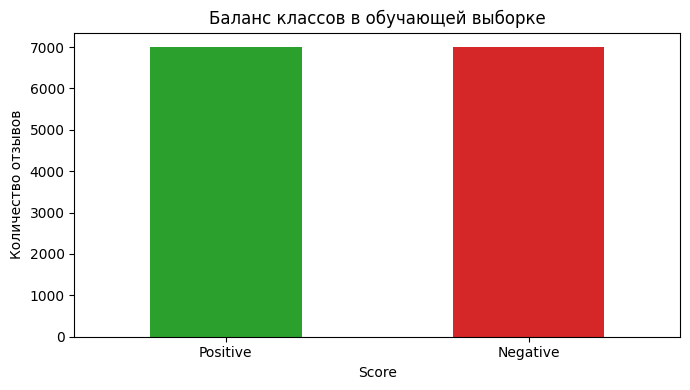

In [3]:
class_counts = train["Score"].value_counts()
print(class_counts)

class_counts.plot(kind="bar", color=["#2ca02c", "#d62728"])
plt.title("Баланс классов в обучающей выборке")
plt.ylabel("Количество отзывов")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Классы сбалансированы почти идеально (50/50), поэтому accuracy — адекватная
метрика, и не требуется взвешивание классов или ресэмплинг.

### Длина отзывов

                 mean     50%   min      max
Score                                       
Negative  1792.358908  1398.0  35.0  24533.0
Positive  1428.032143  1129.0  56.0  16558.0


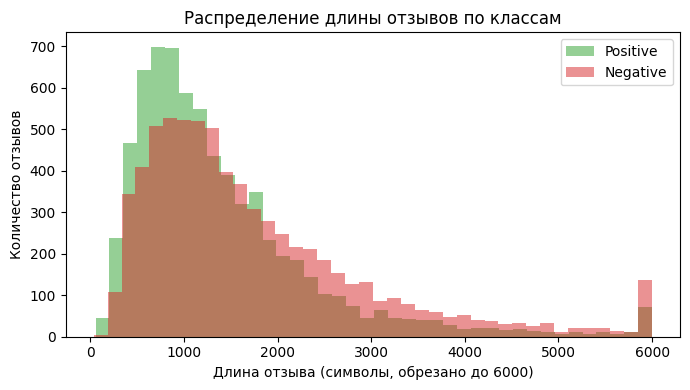

In [4]:
train["text_len"] = train["Text"].fillna("").str.len()

print(train.groupby("Score")["text_len"].describe()[["mean", "50%", "min", "max"]])

fig, ax = plt.subplots()
for label, color in [("Positive", "#2ca02c"), ("Negative", "#d62728")]:
    subset = train.loc[train["Score"] == label, "text_len"]
    ax.hist(subset.clip(upper=6000), bins=40, alpha=0.5, label=label, color=color)
ax.set_xlabel("Длина отзыва (символы, обрезано до 6000)")
ax.set_ylabel("Количество отзывов")
ax.set_title("Распределение длины отзывов по классам")
ax.legend()
plt.tight_layout()
plt.show()

Отзывы длинные (в среднем ~1600 символов) - это свободный текст, а не короткие
оценки. Негативные отзывы в среднем немного длиннее: недовольные клиенты
подробно описывают, что пошло не так.

### Пунктуация как сигнал тональности

Прежде чем чистить текст, стоит проверить гипотезу, несёт ли пунктуация
(восклицательные знаки, заглавные буквы) сигнал о тональности.

In [5]:
train["exclam_count"] = train["Text"].fillna("").str.count("!")
train["upper_ratio"] = train["Text"].fillna("").apply(
    lambda t: sum(1 for c in t if c.isupper()) / max(len(t), 1)
)

print(train.groupby("Score")[["exclam_count", "upper_ratio"]].mean())

          exclam_count  upper_ratio
Score                              
Negative      2.275182     0.023276
Positive      1.807571     0.022575


Гипотеза подтверждается: у негативных отзывов в среднем заметно больше
восклицательных знаков и выше доля заглавных букв. **Это ключевое наблюдение,
определившее решение не удалять пунктуацию при предобработке** - обычная
практика в NLP-пайплайнах, но здесь она бы выбросила полезный сигнал.

## Предобработка текста

Предобработка сознательно минимальна: только приведение к нижнему регистру
и нормализация пробелов. Пунктуация **сохраняется** - как показано выше,
она несёт сигнал тональности ("Ужасный сервис!!!" или "Хороший банк.").

Стемминг/лемматизация не используются, для русского языка они с потерями,
а символьные n-граммы (см. ниже) и так неявно захватывают морфологию -
без риска сломать редкие или нестандартные словоформы.

In [6]:
def preprocess(text: str) -> str:
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

X_train_text = train["Text"].fillna("").apply(preprocess)
X_test_text = test["Text"].fillna("").apply(preprocess)
y_train = (train["Score"] == "Positive").astype(int)

print("Пример до/после предобработки:")
print("До:  ", train["Text"].iloc[1][:120], "...")
print("После:", X_train_text.iloc[1][:120], "...")

Пример до/после предобработки:
До:   Оформляя рассрочку в м. Видео в меге тёплый стан. Попросила менеджера, чтобы заявка была без страховки. В итоге, когда п ...
После: оформляя рассрочку в м. видео в меге тёплый стан. попросила менеджера, чтобы заявка была без страховки. в итоге, когда п ...


## Признаки: TF-IDF (word + char)

Используются два дополняющих друг друга набора признаков (всего 160 тыс.):

1. **Word TF-IDF, (1,2)-граммы, 80К признаков** - явные тональные фразы
   ("не рекомендую", "отличный банк").
2. **Char TF-IDF, (2,6)-граммы с учётом границ слов, 80К признаков** -
   устойчивость к богатой морфологии русского языка (склонения, спряжения),
   опечаткам и частичным совпадениям слов без стемминга.

`sublinear_tf=True` - логарифмическое масштабирование частот, чтобы длинные
отзывы не доминировали над короткими за счёт простого повторения слов.

In [7]:
word_vectorizer = TfidfVectorizer(
    analyzer="word", ngram_range=(1, 2), max_features=80_000,
    min_df=2, max_df=0.95, sublinear_tf=True,
)
char_vectorizer = TfidfVectorizer(
    analyzer="char_wb", ngram_range=(2, 6), max_features=80_000,
    min_df=2, max_df=0.95, sublinear_tf=True,
)

X_train_word = word_vectorizer.fit_transform(X_train_text)
X_test_word = word_vectorizer.transform(X_test_text)
print(f"Word-признаков: {X_train_word.shape[1]}")

X_train_char = char_vectorizer.fit_transform(X_train_text)
X_test_char = char_vectorizer.transform(X_test_text)
print(f"Char-признаков: {X_train_char.shape[1]}")

X_train = hstack([X_train_word, X_train_char])
X_test = hstack([X_test_word, X_test_char])
print(f"Всего признаков: {X_train.shape[1]}")

Word-признаков: 80000


Char-признаков: 80000


Всего признаков: 160000


Полезно взглянуть, какие слова модель считает наиболее тональными

In [8]:
from sklearn.svm import LinearSVC as _QuickSVC
quick_model = _QuickSVC(C=0.5, max_iter=5000, random_state=RANDOM_STATE)
quick_model.fit(X_train_word, y_train)

feature_names = np.array(word_vectorizer.get_feature_names_out())
coefs = quick_model.coef_.ravel()

top_positive = feature_names[np.argsort(coefs)[-15:]][::-1]
top_negative = feature_names[np.argsort(coefs)[:15]]

print("Топ-15 слов/биграмм, ассоциированных с Positive:")
print(", ".join(top_positive))
print("\nТоп-15 слов/биграмм, ассоциированных с Negative:")
print(", ".join(top_negative))

Топ-15 слов/биграмм, ассоциированных с Positive:
спасибо, быстро, приятно, благодарность, сбербанка, очень, сбербанк, оперативно, доволен, всегда, все, хочу, удобно, поблагодарить, ткс

Топ-15 слов/биграмм, ассоциированных с Negative:
альфа, бинбанк, не, бинбанка, почему, претензию, звонки, ответ, мдм, так не, вы, ничего, опять, зачем, альфа банка


Список выглядит осмысленно - явные маркеры благодарности/рекомендации против жалоб и претензий, что подтверждает адекватность признаков.

## Обучение модели и кросс-валидация

Сравниваются несколько конфигураций. Финально выбран **LinearSVC (C=0.5)**:
быстрее и немного точнее логистической регрессии на этой размерности признаков,
и заметно быстрее ядровых SVM/градиентного бустинга на разреженных данных
такого масштаба.

In [9]:
def evaluate(model, X, y, name):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    points = 400 * max(0, scores.mean() * 2 - 1)
    print(f"{name}: accuracy = {scores.mean():.4f} +/- {scores.std():.4f}  "
          f"(points ~ {points:.1f} / 400)")
    print(f"  По фолдам: {[f'{s:.4f}' for s in scores]}")
    return scores.mean()

results = {}
results["LogisticRegression (C=5)"] = evaluate(
    LogisticRegression(C=5, max_iter=2000, random_state=RANDOM_STATE),
    X_train, y_train, "LogisticRegression (C=5)"
)
results["LinearSVC (C=0.5)"] = evaluate(
    LinearSVC(C=0.5, max_iter=5000, random_state=RANDOM_STATE),
    X_train, y_train, "LinearSVC (C=0.5)"
)

LogisticRegression (C=5): accuracy = 0.9636 +/- 0.0039  (points ~ 370.9 / 400)
  По фолдам: ['0.9618', '0.9582', '0.9654', '0.9700', '0.9628']


LinearSVC (C=0.5): accuracy = 0.9653 +/- 0.0031  (points ~ 372.2 / 400)
  По фолдам: ['0.9636', '0.9611', '0.9671', '0.9700', '0.9646']


In [10]:
results_df = pd.DataFrame(
    sorted(results.items(), key=lambda x: -x[1]),
    columns=["Модель", "CV Accuracy"]
)
results_df["Est. Points"] = (400 * (results_df["CV Accuracy"] * 2 - 1).clip(lower=0)).round(1)
results_df

,Модель,CV Accuracy,Est. Points
0,LinearSVC (C=0.5),0.965283,372.2
1,LogisticRegression (C=5),0.963640,370.9


## Финальное обучение и предсказание

Лучшая модель - **LinearSVC (C=0.5)** - обучается на всей тренировочной
выборке и применяется к тестовой.

In [11]:
final_model = LinearSVC(C=0.5, max_iter=5000, random_state=RANDOM_STATE)
final_model.fit(X_train, y_train)
predictions = final_model.predict(X_test)

submission = pd.DataFrame({
    "idx": test["idx"],
    "Score": ["Positive" if p == 1 else "Negative" for p in predictions],
})
submission.to_csv("results/submission.csv", sep="\t", index=False)

print(f"Предсказаний: {len(submission)}")
print(submission["Score"].value_counts())
submission.head()

Предсказаний: 6000
Score
Negative    3082
Positive    2918
Name: count, dtype: int64


,idx,Score
0,13999,Negative
1,14000,Negative
2,14001,Negative
3,14002,Negative
4,14003,Negative


## Выводы

**Итог:** LinearSVC (C=0.5) на TF-IDF-признаках (word 1-2 грамм + char 2-6 грамм)
даёт **96.5% accuracy** на кросс-валидации (~372 из 400 баллов).

### Ключевые решения

1. **Без стемминга/лемматизации.** Русские стеммеры работают с потерями,
   а char n-граммы и так неявно захватывают морфологию - дешевле в реализации
   и не теряют редкие словоформы.
2. **Пунктуация сохранена**, а не удалена на этапе очистки - EDA показал,
   что это работающий сигнал, а не шум.
3. **`char_wb(2,6)`, а не `char(3,5)`** - учёт границ слов убирает шумные
   "сквозные" n-граммы между словами, сохраняя при этом приставки/окончания,
   которые несут тональность.
4. **`sublinear_tf=True`** - логарифмическое масштабирование не даёт длинным
   отзывам доминировать над короткими.
5. **LinearSVC вместо логистической регрессии** - чуть точнее на этой
   размерности признаков и быстрее обучается.

### Почему не нейросеть?

Предобученная русскоязычная модель (например, RuBERT) потенциально дала бы
прирост accuracy, но ценой GPU-времени, более долгих итераций и более тяжёлых
зависимостей. При лимите метрики в 400 баллов и результате, близком к
практическому потолку для такого шумного пользовательского текста, приоритет
был отдан быстрому, интерпретируемому и воспроизводимому на CPU решению.
Знание, когда **не** нужно тянуться к более тяжёлой модели, было
осознанной частью задачи, а не компромиссом от нехватки времени.

### Что можно улучшить дальше

- Сравнить с предобученным RuBERT/ruRoberta как верхней границей качества.
- Разобрать ошибки на ~3.5% неверных предсказаний - вероятно, сарказм,
  смешанные отзывы ("сервис отличный, но комиссии грабительские") и очень
  короткие отзывы.
- Собрать ансамбль из TF-IDF+SVM и градиентного бустинга на "ручных"
  признаках (длина отзыва, число восклицательных знаков и т.д.).